## Import relevent libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\User\Documents\pharmacy_sales_raw.csv")

In [8]:
df.head()

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
0,ORD-101260,2026-03-01 13:32,NaN,CUS00473,Njeri Onyango,0799 297 864,njerionyango@gmail.com,Female,39.0,Nairobi,...,10/2026,134.0,1.0,0.0,NaN,134.0,0.0,Card,4.0,NaN
1,ORD-102354,2026-04-21 15:37,NaN,CUS00404,Mercy Kamau,0746-061-372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,01/2028,373.0,1.0,0.0,NaN,373.0,0.0,M-Pesa,3.0,NaN
2,ORD-105391,2026-09-01 12:30,2026-09-01,CUS01110,Ochieng Mutiso,730127413,ochieng_mutiso@gmail.com,Male,49.0,NAIROBI,...,03/2029,1336.0,3.0,0.0,NaN,4008.0,0.0,M-Pesa,4.0,NaN
3,ORD-100305,2026-01-15 12:47,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,07/2027,1045.0,4.0,5.0,MYDEAL5,3971.0,0.0,M-Pesa,4.0,NaN
4,ORD-103519,2026-06-13 18:13,2026-06-13,CUS01348,Omondi Otieno,+254717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2028,985.0,1.0,20.0,WELL20,788.0,150.0,M-Pesa,3.0,"Fine, nothing special"


## Pre-cleaning EDA

In [9]:
def basic_checks(data):
    print('-' * 40, 'Shape', '-' * 40)
    print(data.shape)
    print('-' * 40, 'Columns', '-' * 40)
    print(data.columns)
    print('-' * 40, 'Duplicates', '-' * 40)
    print(data.duplicated().sum())
    print('-' * 40, 'Info', '-' * 40)
    print(data.info())
    print('-' * 40, 'Nulls', '-' * 40)
    print(data.isnull().sum())
    print('-' * 40, 'Summary Statistics', '-' * 40)
    display(data.describe().T)
    print('-' * 40, 'Summary Categorical Statistics', '-' * 40)
    display(data.describe(include = 'str').T)
    

In [10]:
basic_checks(df)

---------------------------------------- Shape ----------------------------------------
(6150, 26)
---------------------------------------- Columns ----------------------------------------
Index(['order_id', 'order_date', 'delivery_date', 'customer_id',
       'customer_name', 'customer_phone', 'customer_email', 'customer_gender',
       'customer_age', 'city', 'branch', 'channel', 'product_id',
       'product_name', 'category', 'requires_prescription', 'expiry_date',
       'unit_price_kes', 'quantity', 'discount_pct', 'promo_code',
       'total_amount_kes', 'delivery_fee_kes', 'payment_method',
       'customer_rating', 'customer_review'],
      dtype='str')
---------------------------------------- Duplicates ----------------------------------------
120
---------------------------------------- Info ----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype

,count,mean,std,min,25%,50%,75%,max
customer_age,5784.0,34.913900,24.547685,0.00,27.000,34.0,42.0000,999.0
quantity,6056.0,3.516843,21.401592,-5.00,1.000,2.0,3.0000,500.0
discount_pct,6028.0,9.603351,10.747402,-10.00,0.000,10.0,18.0000,150.0
total_amount_kes,6150.0,2359.303434,2881.583637,30.75,491.675,1313.0,3086.1225,22500.0
delivery_fee_kes,6150.0,77.333333,112.349548,0.00,0.000,0.0,200.0000,300.0
customer_rating,4614.0,3.857824,1.156957,0.00,3.000,4.0,5.0000,10.0


---------------------------------------- Summary Categorical Statistics ----------------------------------------


,count,unique,top,freq
order_id,6150,6000,ORD-103590,2
order_date,6150,5887,2026-09-04 18:38,3
delivery_date,2836,276,2026-06-09,21
customer_id,6150,1728,CUS01512,11
customer_name,6028,2348,Sharon Wairimu,20
customer_phone,6025,4420,0757598166,6
customer_email,5963,2176,nyambura.wairimu@safaricom.co.ke,11
customer_gender,5963,2,Female,3728
city,6150,12,Nairobi,3267
branch,6088,11,Nakuru West,618


## Handling the categorical columns

In [11]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6150 non-null   str    
 1   order_date             6150 non-null   str    
 2   delivery_date          2836 non-null   str    
 3   customer_id            6150 non-null   str    
 4   customer_name          6028 non-null   str    
 5   customer_phone         6025 non-null   str    
 6   customer_email         5963 non-null   str    
 7   customer_gender        5963 non-null   str    
 8   customer_age           5784 non-null   float64
 9   city                   6150 non-null   str    
 10  branch                 6088 non-null   str    
 11  channel                6150 non-null   str    
 12  product_id             6150 non-null   str    
 13  product_name           6150 non-null   str    
 14  category               6150 non-null   str    
 15  requires_prescr

None

In [12]:
cat_cols = ['customer_gender', 
            'city', 
            'branch', 
            'channel', 
            'product_name', 
            'category', 
            'requires_prescription', 
            'promo_code', 
            'payment_method', 
            'customer_rating']


In [13]:
for col in cat_cols:
    print('-' * 30, col, '-' * 30)
    print(df[col].nunique()) # Count of unique entries
    print(df[col].unique()) # The actual columns

------------------------------ customer_gender ------------------------------
2
<ArrowStringArray>
['Female', 'Male', nan]
Length: 3, dtype: str
------------------------------ city ------------------------------
12
<ArrowStringArray>
[ 'Nairobi',  'Eldoret',  'NAIROBI',  'Mombasa',   'Kisumu',      'NRB',
   'Nakuru',   'kisumu',  'nairobi', 'Nairobi ',      'MSA',  'mombasa']
Length: 12, dtype: str
------------------------------ branch ------------------------------
11
<ArrowStringArray>
[          'Karen',    'Eldoret Rupa',        'Kilimani',           'Nyali',
 'Thika Road Mall',     'Kisumu Mega',     'Mombasa CBD',     'Nairobi CBD',
          'Online',       'Westlands',     'Nakuru West',               nan]
Length: 12, dtype: str
------------------------------ channel ------------------------------
3
<ArrowStringArray>
['In-store', 'App', 'Online']
Length: 3, dtype: str
------------------------------ product_name ------------------------------
338
<ArrowStringArray>
[          

In [14]:
# Another method

cat_columns = df.select_dtypes(include=['str', 'object']).columns.to_list()
cat_columns

['order_id',
 'order_date',
 'delivery_date',
 'customer_id',
 'customer_name',
 'customer_phone',
 'customer_email',
 'customer_gender',
 'city',
 'branch',
 'channel',
 'product_id',
 'product_name',
 'category',
 'requires_prescription',
 'expiry_date',
 'unit_price_kes',
 'promo_code',
 'payment_method',
 'customer_review']

### Checking for outliers

In [15]:
# checking the pandas version
pd.__version__

'3.0.6'

In [16]:
# Only drop outliers that are by error but retain the natural outlier
# checking for numerical columns

num_cols = df.select_dtypes(include=['float', 'int']).columns.to_list()
num_cols

['customer_age',
 'quantity',
 'discount_pct',
 'total_amount_kes',
 'delivery_fee_kes',
 'customer_rating']

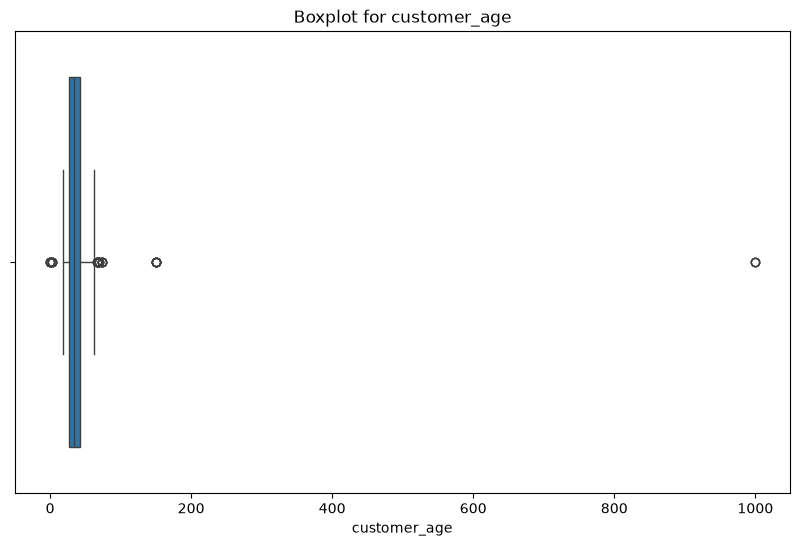

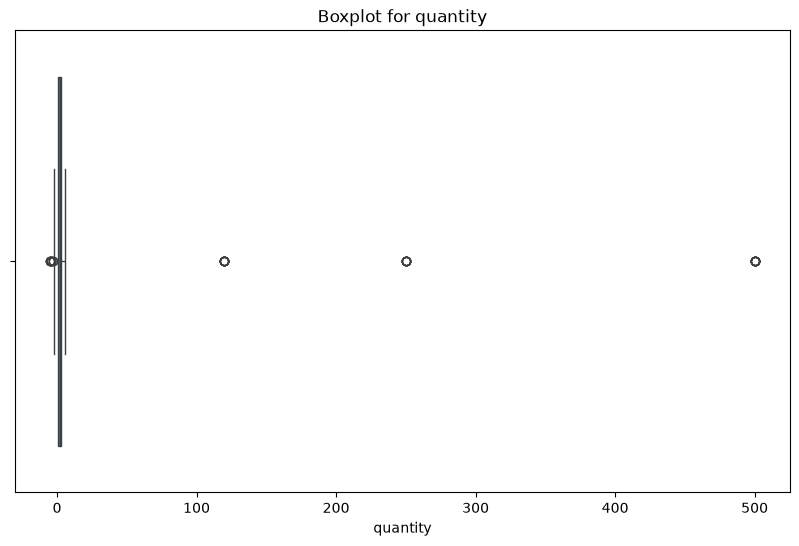

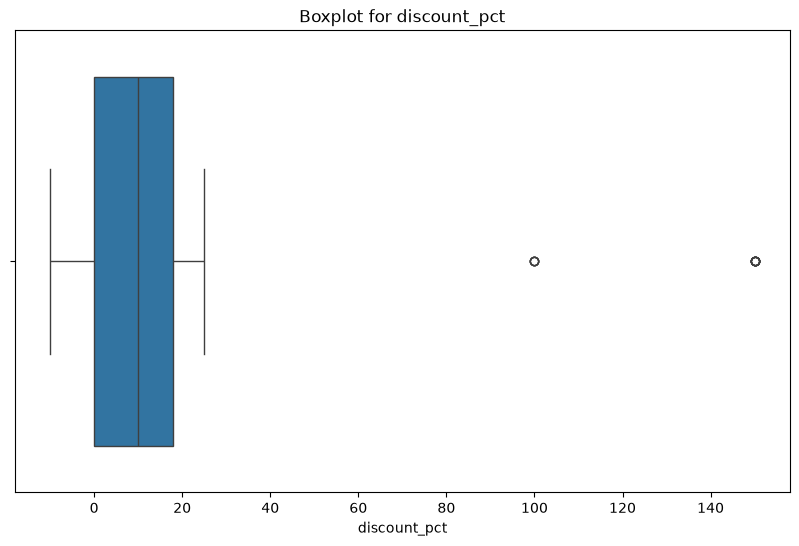

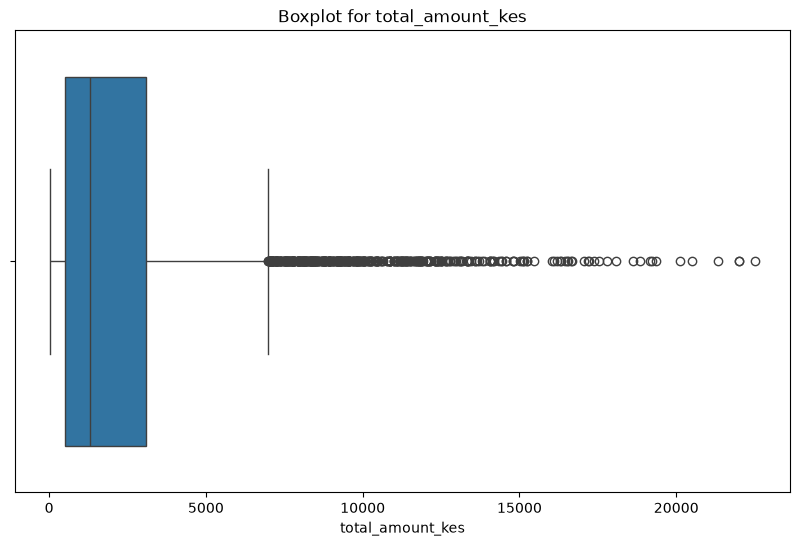

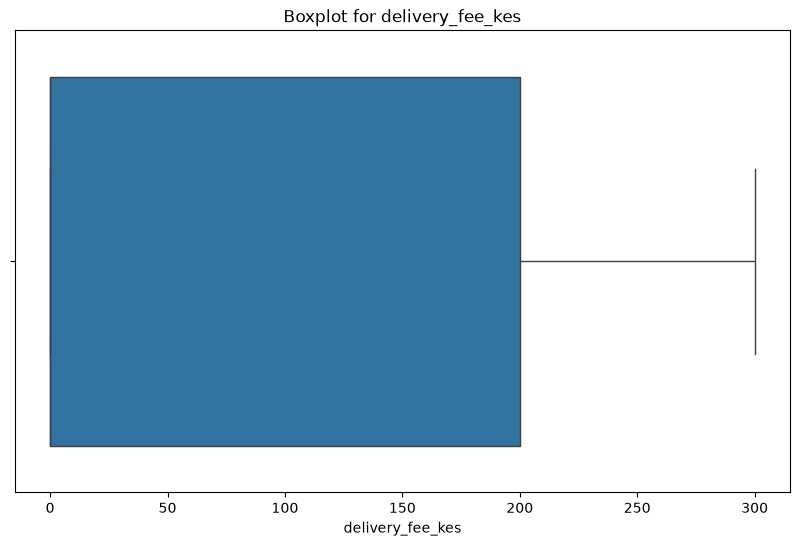

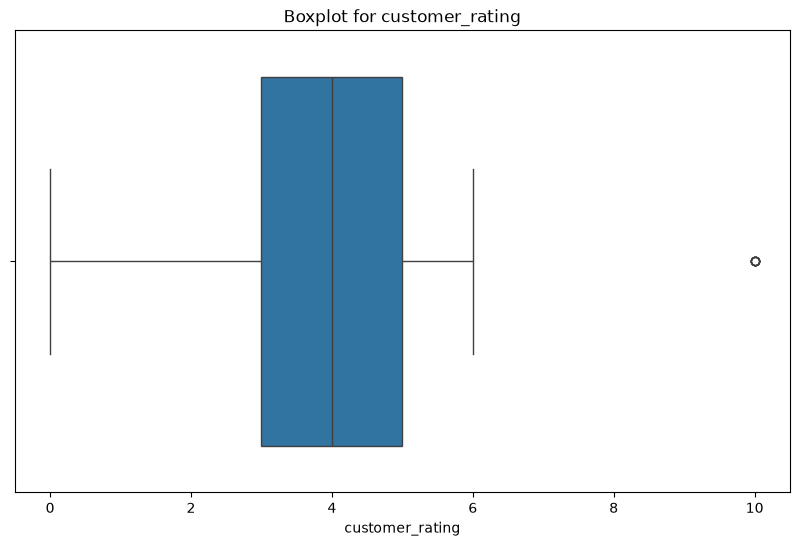

In [17]:
for col in num_cols:
    plt.figure(figsize=(10,6))
    sns.boxplot(df, x=col)
    plt.title(f"Boxplot for {col}")
    plt.show()


In [ ]:
# creating a duplicate 
sales_data_copy = df.copy()

In [20]:
df['category'].unique()

<ArrowStringArray>
[          'Personal Care',           'Personal care',
              'Cold & Flu', 'Supplements & Nutrition',
              'Mum & Baby',           'PERSONAL CARE',
 'Dermatological Skincare',     'Pain & Inflammation',
      'Beauty & Skin Care',           'personal care',
         'Family Planning',            'Mum and Baby',
     'PAIN & INFLAMMATION',         'Medical Devices',
             ' Cold & Flu', 'supplements & nutrition',
     'pain & inflammation',              'cold & flu',
   'Pain and Inflammation',             'Mum & Baby ',
             'Supplements',            'Cold and Flu',
             'COLD & FLU ',              'mum & baby']
Length: 24, dtype: str

In [ ]:
df["city"] = df["city"].replace({
    "NAIROBI" : "Nairobi",
    "NRB" : "Nairobi",
    "nairobi": "Nairobi",
    "Nairobi " : "Nairobi",
    "MSA" : "Mombasa",
    "mombasa" : "Mombasa",
    "kisumu" : "Kisumu"
})
df['city'].unique()

In [22]:
df['city'].unique()

<ArrowStringArray>
['Nairobi', 'Eldoret', 'Mombasa', 'Kisumu', 'Nakuru']
Length: 5, dtype: str

In [40]:

# df.describe()
# This executes the function to calculate summary statistics
# (count, mean, std, min, 25%, 50%, 75%, max) for all numerical columns in your DataFrame.
df.describe()



df.describe().T
# The .T property stands for Transpose.
#  It flips the matrix on its side. Your features 
#  become rows on the left, and the statistical metrics 
#  become columns across the top.


,count,mean,std,min,25%,50%,75%,max
customer_age,5784.0,34.913900,24.547685,0.00,27.000,34.0,42.0000,999.0
quantity,6056.0,3.516843,21.401592,-5.00,1.000,2.0,3.0000,500.0
discount_pct,6028.0,9.603351,10.747402,-10.00,0.000,10.0,18.0000,150.0
total_amount_kes,6150.0,2359.303434,2881.583637,30.75,491.675,1313.0,3086.1225,22500.0
delivery_fee_kes,6150.0,77.333333,112.349548,0.00,0.000,0.0,200.0000,300.0
customer_rating,4614.0,3.857824,1.156957,0.00,3.000,4.0,5.0000,10.0


In [29]:
df['category'].unique()

<ArrowStringArray>
[          'Personal Care',           'Personal care',
              'Cold & Flu', 'Supplements & Nutrition',
              'Mum & Baby',           'PERSONAL CARE',
 'Dermatological Skincare',     'Pain & Inflammation',
      'Beauty & Skin Care',           'personal care',
         'Family Planning',            'Mum and Baby',
     'PAIN & INFLAMMATION',         'Medical Devices',
             ' Cold & Flu', 'supplements & nutrition',
     'pain & inflammation',              'cold & flu',
   'Pain and Inflammation',             'Mum & Baby ',
             'Supplements',            'Cold and Flu',
             'COLD & FLU ',              'mum & baby']
Length: 24, dtype: str

In [30]:
df['category'] = df['category'].str.capitalize().str.strip()

In [31]:
df['category'].unique()

<ArrowStringArray>
[          'Personal care',              'Cold & flu',
 'Supplements & nutrition',              'Mum & baby',
 'Dermatological skincare',     'Pain & inflammation',
      'Beauty & skin care',         'Family planning',
            'Mum and baby',         'Medical devices',
              'cold & flu',   'Pain and inflammation',
             'Supplements',            'Cold and flu']
Length: 14, dtype: str

In [32]:
df['category'] = df['category'].replace(
    {'Mum and baby' : 'Mum & baby',
     'cold & flu' : 'cold & flu',
     'Cold & flu' : 'cold & flu',
     'Cold and flu' : 'cold & flu',
     'Supplements' : 'Supplements & nutrition',
     'Pain and inflammation' : 'Pain & inflammation' 
      }
)

In [33]:
df['category'].unique()

<ArrowStringArray>
[          'Personal care',              'cold & flu',
 'Supplements & nutrition',              'Mum & baby',
 'Dermatological skincare',     'Pain & inflammation',
      'Beauty & skin care',         'Family planning',
         'Medical devices']
Length: 9, dtype: str

In [6]:
# requires prescription column
df["requires_prescription"].unique()

<ArrowStringArray>
['No', 'FALSE', '0', 'N', 'no', 'Y', 'TRUE', 'Yes', 'yes', '1']
Length: 10, dtype: str

In [3]:
df["requires_prescription"] = df["requires_prescription"].astype(str).str.strip().str.capitalize()


In [10]:
df["requires_prescription"].unique()

<ArrowStringArray>
['False', 'True']
Length: 2, dtype: str

In [9]:
df["requires_prescription"] =df["requires_prescription"].replace(
    {
        'No' : 'False',
         '0' : 'False',
         'N' : 'False',
         'Yes' : 'True',
         '1' : 'True',
         'Y' : 'True'

    }
)

In [19]:
df["payment_method"].unique()

<ArrowStringArray>
['Card', 'M-pesa', 'Insurance', nan, 'Cash']
Length: 5, dtype: str

In [12]:
df["payment_method"] = df["payment_method"].str.strip().str.capitalize()

In [ ]:
df["payment_method"] = df["payment_method"].replace(
    {
        'Mpesa' : 'M-pesa',
        'Visa' : 'Card'
    }
)

In [20]:
# promocodes column(
df["promo_code"] = df["promo_code"].str.strip().str.upper()

In [24]:
df["promo_code"].unique()

<ArrowStringArray>
[       nan,  'MYDEAL5',   'WELL20',   'GLOW25', 'MYDEAL18',   'WELL15',
   'SAVE10',   'WELL25',   'GLOW18',    'GLOW5',  'HEALTH5',   'WELL10',
   'GLOW10', 'MYDEAL10',   'GLOW15', 'MYDEAL25', 'HEALTH25',    'SAVE5',
   'SAVE20',   'WELL18', 'HEALTH18', 'MYDEAL20',   'SAVE25',   'SAVE18',
    'WELL5',   'SAVE15', 'HEALTH15', 'HEALTH20',   'GLOW20', 'HEALTH10',
 'MYDEAL15']
Length: 31, dtype: str

In [23]:
df["promo_code"] = df["promo_code"].str.replace(r'[\s-]', '', regex=True)

In [25]:
df["product_name"].unique()

<ArrowStringArray>
[           'Kotex Ultra Sanitary Pads Super 8's',
        'Nivea Rich Nourishing Body Lotion 200ml',
                    'Olbas Oil For Children 12ml',
                 'Seven Seas Cod Liver Oil 100ml',
                    'NipNap Diaper Junior 5 36's',
                 'Nivea Deo Spray Espresso 150ml',
                           'Oligocare Forte 20's',
 'La Roche-Posay Effaclar Foaming Cleanser 200ml',
               'Fay Antibacterial Wet Wipes 72's',
                           'Zefcolin Syrup 100ml',
 ...
                     '  Aptamil Baby Milk 2 800g',
          '  Panadol Advance 500mg Tablets 100's',
            'Endosan Maternity Pads Large 10's  ',
                          '  Coldcap Syrup 100ml',
                 'Centrum Men 50+ Tablets 30's  ',
    '  Uncover Argan Hydrating Moisturizer 100ml',
                       '  Epimol-E Soap Bar 100g',
        'Panadol Cold & Flu Night Tablets 24's  ',
                        'Wellbaby Liquid 150ml  ',
   'Opt

In [26]:
df["product_name"] = df["product_name"].str.strip().str.capitalize()

In [27]:
df["product_name"].unique()

<ArrowStringArray>
[           'Kotex ultra sanitary pads super 8's',
        'Nivea rich nourishing body lotion 200ml',
                    'Olbas oil for children 12ml',
                 'Seven seas cod liver oil 100ml',
                    'Nipnap diaper junior 5 36's',
                 'Nivea deo spray espresso 150ml',
                           'Oligocare forte 20's',
 'La roche-posay effaclar foaming cleanser 200ml',
               'Fay antibacterial wet wipes 72's',
                           'Zefcolin syrup 100ml',
 ...
                'Cerave blemish control gel 40ml',
                         'Dr browns silicone bib',
            'Nice & lovely baby range value pack',
    'Cinnabar body lotion geranium & lavender 1l',
  'Eucerin sun even pigment perfector fluid 50ml',
                'Cerave hydrating cleanser 473ml',
                      'Lyrica 75mg capsules 28's',
        'La roche-posay lipikar baume ap+m 200ml',
                    'Panadol extra tablets 100's',
      '

In [47]:
df.sample(10, random_state = 30)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
3487,ORD-104784,2026-08-06 17:33,NaN,CUS00054,Achieng Chege,0794096817,achieng_chege33@gmail.com,Female,48.0,Nairobi,...,06/2028,"KES 2,074",2.0,10.0,WELL10,3733.20,0.0,Cash,4.0,NaN
2764,ORD-101596,2026-03-17 10:18,2026-03-18,CUS00384,Dennis Mutiso,254752064254,dennismutiso89@gmail.com,Male,34.0,Nairobi,...,05/2027,1577.0,1.0,20.0,MYDEAL20,1261.60,300.0,Card,5.0,
4821,ORD-102493,2026-04-28 11:46,2026-04-28,CUS01457,Muthoni Hassan,0795 031 174,muthonihassan29@students.uonbi.ac.ke,Female,31.0,Nairobi,...,12/2026,201.0,1.0,0.0,NaN,201.00,250.0,M-pesa,4.0,WORKS WELL FOR MY FAMILY
3514,ORD-104320,2026-07-18 19:32,NaN,CUS00352,Njeri Omondi,+254747263214,njeri_omondi27@gmail.com,Female,NaN,Kisumu,...,01/2028,110.0,1.0,18.0,WELL18,90.20,0.0,M-pesa,NaN,NaN
5519,ORD-102630,2026-05-06 08:19,2026-05-06,CUS00181,Njoroge Mwangi,0758315140,njoroge.mwangi87@students.uonbi.ac.ke,Male,28.0,NAIROBI,...,05/2027,4105.0,1.0,10.0,GLOW10,3694.50,0.0,Card,4.0,Easy to pay with M-Pesa
5698,ORD-100090,2026-01-05 10:49,NaN,CUS01348,Omondi Otieno,0717 136 055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2027,NaN,3.0,15.0,SAVE15,311.10,0.0,Cash,5.0,NaN
2142,ORD-104404,2026-07-22 12:19,2026-07-24,CUS01242,Atieno Wekesa,0191 251 714,atieno_wekesa@gmail.com,Female,27.0,Eldoret,...,08/2027,6382.0,1.0,18.0,MYDEAL18,5233.24,0.0,Insurance,5.0,Delivered to my office in Westlands within hours
5772,ORD-102377,2026-04-22 17:59,2026-04-23,CUS01045,Achieng Mohamed,793860777,achieng_mohamed@gmail.com,Female,37.0,Nairobi,...,05/2027,1735.0,2.0,0.0,NaN,3470.00,0.0,M-pesa,5.0,NaN
813,ORD-102428,2026-04-25 08:19,NaN,CUS00359,Achieng Odhiambo,0749800319,achieng_odhiambo2@outlook.com,Female,20.0,Nairobi,...,06/2028,1991.0,2.0,0.0,NaN,3982.00,0.0,M-pesa,10.0,NaN
2498,ORD-104358,2026-07-20 17:13,NaN,CUS01030,Akinyi Kiptoo,254765462927,AKINYI.KIPTOO81@GMAIL.COM,Female,19.0,Kisumu,...,08/2028,548.0,5.0,18.0,MYDEAL18,2246.80,0.0,M-pesa,NaN,NaN


In [ ]:
df["customer_name"] = df["customer_name"].str.strip().str.title()


In [45]:
df['customer_name'] = df['customer_name'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()

<ArrowStringArray>
[  'Njeri Onyango',     'Mercy Kamau',  'Ochieng Mutiso',  'Barasa Wanjala',
   'Omondi Otieno',    'Atieno Maina',   'Wambui Otieno', 'Muthoni Kilonzo',
      'Faith Ruto',   'Mutua Achieng',
 ...
 'Kipchoge Langat',  'Purity Kilonzo',     'Allan Nduta',  'Barasa Njoroge',
    'Peter Ndungu',    'Barasa Maina',  'Samuel Mohamed',   'Kiprono Chege',
 'Kipchoge Mutiso',     'Chebet Ruto']
Length: 943, dtype: str

In [53]:
df.head(10)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
0,ORD-101260,2026-03-01 13:32,NaN,CUS00473,Njeri Onyango,0799 297 864,njerionyango@gmail.com,Female,39.0,Nairobi,...,10/2026,134.0,1.0,0.0,NaN,134.0,0.0,Card,4.0,None
1,ORD-102354,2026-04-21 15:37,NaN,CUS00404,Mercy Kamau,0746-061-372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,01/2028,373.0,1.0,0.0,NaN,373.0,0.0,M-pesa,3.0,None
2,ORD-105391,2026-09-01 12:30,2026-09-01,CUS01110,Ochieng Mutiso,730127413,ochieng_mutiso@gmail.com,Male,49.0,NAIROBI,...,03/2029,1336.0,3.0,0.0,NaN,4008.0,0.0,M-pesa,4.0,None
3,ORD-100305,2026-01-15 12:47,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,07/2027,1045.0,4.0,5.0,MYDEAL5,3971.0,0.0,M-pesa,4.0,None
4,ORD-103519,2026-06-13 18:13,2026-06-13,CUS01348,Omondi Otieno,+254717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2028,985.0,1.0,20.0,WELL20,788.0,150.0,M-pesa,3.0,"Fine, nothing special"
5,ORD-103590,2026-06-16 19:20,NaN,CUS01683,Atieno Maina,+254725565732,NaN,Female,61.0,Eldoret,...,10/2027,373.0,2.0,0.0,NaN,746.0,0.0,M-pesa,NaN,None
6,ORD-104051,2026-07-07 19:04,2026-07-12,CUS00324,Wambui Otieno,0764 206 790,wambui_otieno48@gmail.com,Female,52.0,Kisumu,...,11/2028,777.0,2.0,25.0,GLOW25,1165.5,150.0,M-pesa,3.0,"Fine, nothing special"
7,ORD-104798,2026-08-07 17:15,2026-08-08,CUS00424,Muthoni Kilonzo,+254739443335,muthoni.kilonzo@gmail.com,Female,18.0,Nairobi,...,09/2028,1328.0,1.0,0.0,NaN,1328.0,250.0,M-pesa,4.0,"Poa sana, packaging was neat"
8,ORD-105559,2026-09-09 18:40,NaN,CUS01312,Faith Ruto,+254796480456,faith_ruto47@gmail.com,Female,55.0,Mombasa,...,04/2027,2821.0,1.0,0.0,NaN,2821.0,0.0,Card,NaN,None
9,ORD-100246,2026-01-12 16:18,NaN,CUS01666,Mutua Achieng,0768 838 383,mutuaachieng@gmail.com,Male,33.0,Nairobi,...,04/2028,181.0,3.0,0.0,NaN,543.0,0.0,M-pesa,NaN,None


In [52]:
df["customer_review"] = (
    df["customer_review"]
    .str.strip()
    .str.capitalize()
    .str.replace("-", "None")
    .replace("", "None")
    .fillna("None")
)

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6150 non-null   str    
 1   order_date             6150 non-null   str    
 2   delivery_date          2836 non-null   str    
 3   customer_id            6150 non-null   str    
 4   customer_name          6028 non-null   str    
 5   customer_phone         6025 non-null   str    
 6   customer_email         5963 non-null   str    
 7   customer_gender        5963 non-null   str    
 8   customer_age           5784 non-null   float64
 9   city                   6150 non-null   str    
 10  branch                 6088 non-null   str    
 11  channel                6150 non-null   str    
 12  product_id             6150 non-null   str    
 13  product_name           6150 non-null   str    
 14  category               6150 non-null   str    
 15  requires_prescr

In [56]:
df["order_id"].duplicated().sum()

np.int64(150)

In [58]:
df.duplicated().sum()

np.int64(120)

In [61]:
df_clean = df.drop_duplicates()

In [63]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6030 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6030 non-null   str    
 1   order_date             6030 non-null   str    
 2   delivery_date          2790 non-null   str    
 3   customer_id            6030 non-null   str    
 4   customer_name          5910 non-null   str    
 5   customer_phone         5909 non-null   str    
 6   customer_email         5849 non-null   str    
 7   customer_gender        5848 non-null   str    
 8   customer_age           5671 non-null   float64
 9   city                   6030 non-null   str    
 10  branch                 5970 non-null   str    
 11  channel                6030 non-null   str    
 12  product_id             6030 non-null   str    
 13  product_name           6030 non-null   str    
 14  category               6030 non-null   str    
 15  requires_prescriptio

In [67]:
df["order_date"].info

<bound method Series.info of 0      2026-01-03 13:32:00
1      2026-04-21 15:37:00
2      2026-01-09 12:30:00
3      2026-01-15 12:47:00
4      2026-06-13 18:13:00
               ...        
6145   2026-09-16 13:55:00
6146   2026-01-05 10:09:00
6147   2026-01-25 17:45:00
6148   2026-02-27 17:51:00
6149   2026-07-16 14:40:00
Name: order_date, Length: 6150, dtype: datetime64[us]>

In [66]:
df["order_date"] = pd.to_datetime(df["order_date"], format ="mixed", dayfirst=True, errors="coerce")

In [68]:
df['customer_phone'] = (
    df['customer_phone']
    .astype('string')
    .str.strip()
    .str.replace(r'[\s-]+', '', regex=True)
    .str.replace(r'^\+254', '0', regex=True)
    .str.replace(r'^254', '0', regex=True)
    .str.replace(r'^(7\d{8})$', r'0\1', regex=True)
)